<a href="https://colab.research.google.com/github/DalilaGallegos/Portafolio-Diplomado-en-Python-Gallegos-Jimenez-Yajaira-Dalila/blob/main/01_Analisis_Exploratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diplomado: Programación en Python para la web y el analsis de datos

## Portafolio de Evidencias de Aprendizaje

### Notebook 1. Análisis exploratorio de datos para un problema de clasificación

**Proyecto:** Análisis del abandono de clientes en una empresa de telecomunicaciones  
**Conjunto de datos:** Telco Customer Churn  
**Metodología:** CRISP-DM  
**Fases desarrolladas:** Comprensión del negocio y Comprensión de los datos  
**Tipo de problema:** Clasificación binaria  
**Variable objetivo:** `Churn`

**Nombre del estudiante:** Yajaira Dalila Gallegos Jiménez

# Introducción

El abandono de clientes, conocido como *customer churn*, representa una situación relevante para las empresas de servicios, ya que ocurre cuando un usuario decide finalizar su relación comercial con una compañía.

El análisis de información histórica sobre los clientes puede ayudar a comprender qué características aparecen con mayor frecuencia entre quienes permanecen y quienes abandonan un servicio. Para ello, la ciencia de datos permite explorar grandes cantidades de información, identificar patrones y obtener hallazgos que posteriormente podrían servir como base para desarrollar modelos de clasificación.

En este notebook se realizará un análisis exploratorio del conjunto de datos **Telco Customer Churn**, aplicando las primeras dos fases de la metodología CRISP-DM: **Comprensión del negocio (Business Understanding)** y **Comprensión de los datos (Data Understanding)**.

Durante el desarrollo se analizará la estructura del conjunto de datos, las variables disponibles, sus tipos de datos, estadísticas descriptivas, valores faltantes, registros duplicados y la distribución de la variable objetivo. También se generarán diferentes visualizaciones para estudiar algunos patrones relacionados con el abandono de clientes.

El alcance de esta actividad será exclusivamente exploratorio. No se realizará preparación orientada al modelado, entrenamiento de algoritmos ni evaluación predictiva.

# Objetivo

Analizar las características de los clientes de una empresa de telecomunicaciones mediante las fases de **Comprensión del negocio** y **Comprensión de los datos** de la metodología CRISP-DM, con el propósito de conocer la estructura y calidad del conjunto de datos e identificar patrones asociados con el abandono del servicio.

# 1. Comprensión del negocio

## 1.1 Descripción del problema

El conjunto de datos **Telco Customer Churn** contiene información relacionada con clientes de una empresa de telecomunicaciones. Incluye características personales, antigüedad como cliente, servicios contratados, tipo de contrato, método de pago y cargos relacionados con el servicio.

Uno de los problemas que puede enfrentar una empresa de telecomunicaciones es la pérdida de clientes. Cuando un usuario decide cancelar sus servicios y abandonar la compañía se produce lo que se conoce como **Churn**.

Analizar las características de los clientes que permanecen y de aquellos que abandonan puede permitir identificar patrones relacionados con este comportamiento.

## 1.2 Importancia y contexto

La pérdida de clientes puede afectar a una empresa debido a la reducción de usuarios y de los ingresos relacionados con los servicios contratados.

Por esta razón, resulta útil analizar si existen determinadas características de los clientes, de sus contratos o de los servicios utilizados que se presenten con mayor frecuencia entre quienes abandonan la compañía.

Comprender estos patrones puede proporcionar información que posteriormente permita orientar estrategias de atención y retención de clientes.

Este análisis no pretende determinar las causas del abandono, sino identificar patrones y asociaciones existentes dentro de los datos disponibles.

## 1.3 Pregunta de análisis

La pregunta principal que orientará el análisis es:

**¿Existen características de los clientes y de los servicios que tienen contratados que se encuentren asociadas con el abandono de la compañía de telecomunicaciones?**

## 1.4 Objetivo general del proyecto

Analizar las características de los clientes de una empresa de telecomunicaciones mediante las fases de comprensión del negocio y comprensión de los datos de la metodología CRISP-DM, con el propósito de conocer el conjunto de datos e identificar patrones que puedan estar asociados con el abandono del servicio.

## 1.5 Variable que se pretende clasificar

La variable de interés es `Churn`, la cual indica si un cliente abandonó o permaneció en la compañía.

Esta variable presenta dos categorías:

- `No`: el cliente permaneció en la compañía.
- `Yes`: el cliente abandonó la compañía.

Debido a que existen únicamente dos posibles categorías, se trata de un **problema de clasificación binaria**.

## 1.6 Utilidad del análisis

La información obtenida mediante este análisis podría utilizarse posteriormente como base para desarrollar modelos predictivos orientados a identificar clientes con mayor riesgo estimado de abandonar el servicio.

También podría aportar información útil para estudiar estrategias relacionadas con atención al cliente, condiciones de contratación y retención.

Sin embargo, las relaciones encontradas durante el análisis exploratorio deben interpretarse como asociaciones presentes en los datos y no necesariamente como relaciones de causa y efecto.

# 2. Comprensión de los datos

En esta etapa se explorará el conjunto de datos para conocer su estructura, dimensiones, variables, tipos de datos y distribución.

También se revisará la presencia de valores faltantes, registros duplicados y posibles inconsistencias. Posteriormente se obtendrán estadísticas descriptivas y se generarán visualizaciones que permitan comprender mejor el comportamiento de los datos y de la variable objetivo `Churn`.

## 2.1 Origen del conjunto de datos

El conjunto de datos utilizado es **Telco Customer Churn**, obtenido de la plataforma Kaggle.

El archivo utilizado se denomina:

`WA_Fn-UseC_-Telco-Customer-Churn.csv`

Cada registro representa a un cliente de una empresa de telecomunicaciones y las columnas contienen información relacionada con sus características personales, servicios contratados, condiciones comerciales, facturación y comportamiento de abandono.

## 2.2 Importación de las librerías

Para realizar el análisis se utilizarán las siguientes bibliotecas:

- **Pandas:** para cargar, explorar y analizar los datos.
- **Matplotlib:** para generar visualizaciones.
- **Seaborn:** para crear gráficos estadísticos de manera sencilla.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.3 Conexión con Google Drive

El archivo CSV se encuentra almacenado en Google Drive. Por esta razón, se conectará Google Colab con Drive para poder acceder al conjunto de datos.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2.4 Carga del conjunto de datos

El archivo será importado mediante la función `read_csv()` de Pandas y almacenado en un DataFrame denominado `df`.

Posteriormente se utilizará `head()` para visualizar los primeros registros y comprobar que los datos fueron cargados correctamente.

In [3]:
ruta = "/content/drive/MyDrive/Diplomado/Proyecto: Redes Neuronales/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(ruta)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


La visualización de las primeras filas permite comprobar que el archivo fue cargado correctamente y observar de manera preliminar cómo se encuentran organizados los registros y las variables.

Se identifican tanto variables relacionadas con características personales del cliente como información sobre servicios, contratos, pagos y cargos.

## 2.5 Dimensiones del conjunto de datos

Se utilizará el atributo `shape` para identificar el número total de registros y variables presentes en el conjunto de datos.

In [4]:
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 7043
Número de variables: 21


El conjunto de datos contiene **7,043 registros y 21 variables**.

Cada fila representa a un cliente de la empresa de telecomunicaciones, mientras que cada columna corresponde a una característica relacionada con el cliente, los servicios contratados o su relación comercial con la compañía.

## 2.6 Identificación de las variables

Con la siguiente línea de código se mostrarán los nombres de las variables que forman parte del conjunto de datos.

In [5]:
for i, columna in enumerate(df.columns, start=1):
    print(f"{i}. {columna}")

1. customerID
2. gender
3. SeniorCitizen
4. Partner
5. Dependents
6. tenure
7. PhoneService
8. MultipleLines
9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


## 2.7 Significado de las principales variables

Las variables del conjunto de datos incluyen información demográfica, servicios contratados, condiciones comerciales y datos de facturación.

| Variable | Significado |
|---|---|
| `customerID` | Identificador único del cliente |
| `gender` | Género del cliente |
| `SeniorCitizen` | Indica si el cliente es adulto mayor |
| `Partner` | Indica si el cliente tiene pareja |
| `Dependents` | Indica si tiene personas dependientes |
| `tenure` | Cantidad de meses que lleva como cliente |
| `PhoneService` | Indica si tiene servicio telefónico |
| `MultipleLines` | Indica si tiene múltiples líneas telefónicas |
| `InternetService` | Tipo de servicio de Internet contratado |
| `OnlineSecurity` | Indica si cuenta con seguridad en línea |
| `OnlineBackup` | Indica si cuenta con respaldo en línea |
| `DeviceProtection` | Indica si cuenta con protección de dispositivos |
| `TechSupport` | Indica si cuenta con soporte técnico |
| `StreamingTV` | Indica si tiene servicio de televisión por streaming |
| `StreamingMovies` | Indica si tiene servicio de películas por streaming |
| `Contract` | Tipo de contrato del cliente |
| `PaperlessBilling` | Indica si utiliza facturación electrónica |
| `PaymentMethod` | Método utilizado para realizar los pagos |
| `MonthlyCharges` | Cargo mensual realizado al cliente |
| `TotalCharges` | Cantidad total acumulada cobrada al cliente |
| `Churn` | Indica si el cliente abandonó o permaneció en la compañía |

## 2.8 Tipos de datos

Se utilizará `info()` para revisar los tipos de datos, el número de registros y la cantidad de valores no nulos en cada variable.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


El conjunto de datos contiene variables numéricas y variables almacenadas como texto.

Se observa especialmente que `TotalCharges`, aunque conceptualmente representa una cantidad monetaria, aparece almacenada como tipo `object`. Esto indica que podrían existir valores dentro de la columna que impiden que Pandas la reconozca como numérica.

También se observa que `SeniorCitizen` está almacenada como una variable numérica porque utiliza los valores 0 y 1, aunque conceptualmente representa una variable categórica binaria.

La identificación de estas características es importante porque permite conocer la forma en que los datos están almacenados antes de realizar cualquier análisis posterior.

## 2.9 Estadísticas descriptivas de las variables numéricas

Se utilizará `describe()` para obtener diferentes medidas estadísticas de las variables reconocidas inicialmente como numéricas.

Entre los resultados se encuentran:

- cantidad de observaciones;
- promedio;
- desviación estándar;
- valor mínimo;
- primer cuartil;
- mediana;
- tercer cuartil;
- valor máximo.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Las estadísticas descriptivas permiten observar la distribución general de las variables numéricas.

Entre las variables reconocidas inicialmente como numéricas se encuentran `SeniorCitizen`, `tenure` y `MonthlyCharges`.

La variable `tenure` muestra la cantidad de meses que cada persona ha permanecido como cliente, mientras que `MonthlyCharges` representa el cargo mensual asociado con los servicios contratados.

Estas medidas permiten conocer rangos, tendencias centrales y variabilidad dentro de los datos.

## 2.9.1 Distribución de las variables numéricas

Además de las estadísticas descriptivas, resulta útil observar gráficamente la distribución de las variables numéricas.

Los histogramas permiten identificar aspectos como:

- Concentración de los valores.
- Dispersión.
- Asimetrías.
- Posibles valores extremos.
- Diferencias en las escalas de las variables.

Para este análisis se utilizarán las variables `SeniorCitizen`, `tenure`, `MonthlyCharges` y `TotalCharges`.

Debido a que `TotalCharges` se encuentra almacenada originalmente como texto, se creará únicamente una copia auxiliar para convertir esta variable a formato numérico con fines de visualización. Esta operación no modifica el DataFrame original ni constituye todavía una preparación de datos para modelado.

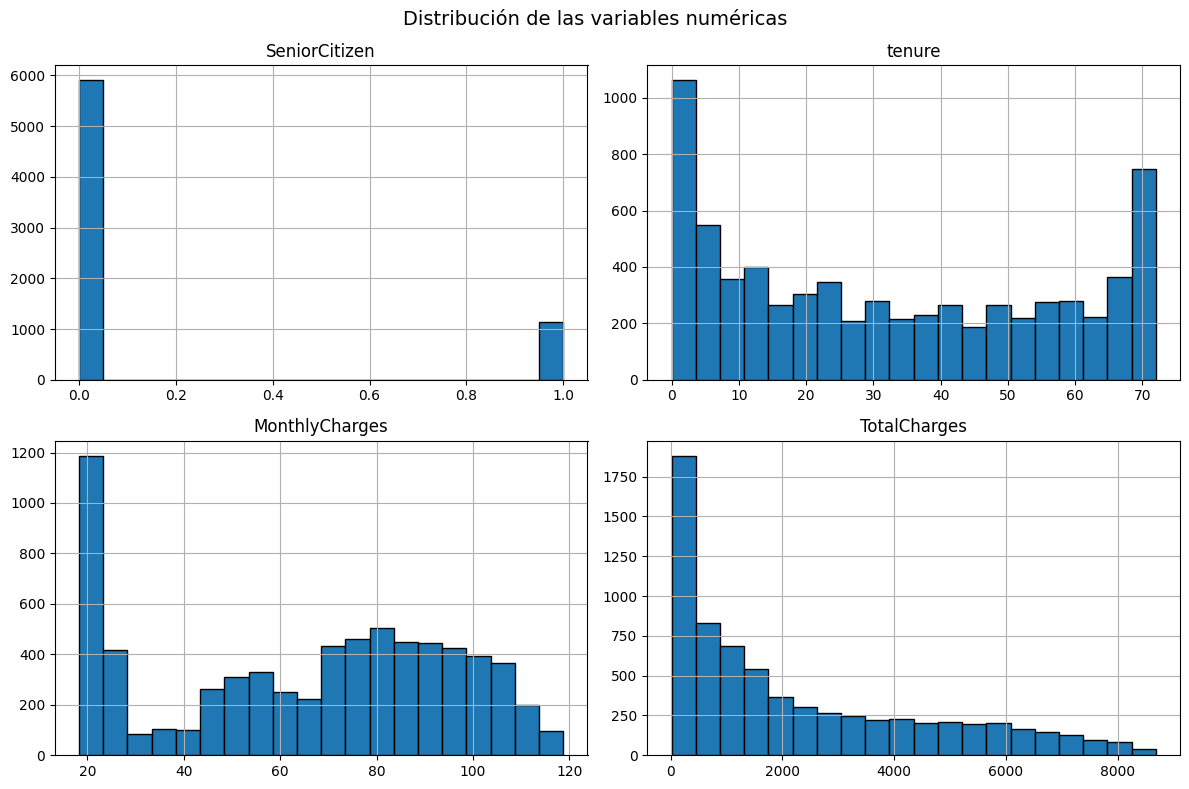

In [8]:
# Se crea una copia únicamente para el análisis gráfico
df_hist = df.copy()

# Conversión temporal de TotalCharges para poder visualizar su distribución
df_hist["TotalCharges"] = pd.to_numeric(
    df_hist["TotalCharges"],
    errors="coerce"
)

variables_numericas = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df_hist[variables_numericas].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribución de las variables numéricas",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretación de las distribuciones

Los histogramas permiten observar que las variables numéricas no presentan el mismo tipo de distribución.

`SeniorCitizen` funciona realmente como una variable binaria codificada mediante 0 y 1, por lo que su distribución refleja principalmente la cantidad de clientes adultos mayores y no adultos mayores.

La variable `tenure` presenta clientes distribuidos a lo largo de diferentes niveles de antigüedad, desde usuarios recientes hasta clientes con varios años dentro de la compañía.

`MonthlyCharges` muestra una amplia variedad de cargos mensuales, lo cual puede relacionarse con las diferentes combinaciones de servicios contratados.

Por su parte, `TotalCharges` presenta una distribución más dispersa debido a que representa el gasto acumulado del cliente y se encuentra relacionado tanto con los cargos mensuales como con el tiempo que lleva utilizando los servicios.

Estas diferencias muestran que las variables numéricas poseen escalas y comportamientos distintos, aspecto que sería relevante si posteriormente se continuara con una etapa de preparación y modelado.

## 2.10 Estadísticas descriptivas de las variables categóricas

También se analizarán las variables almacenadas como tipo `object`.

Para estas variables, `describe()` permite conocer:

- cantidad de registros;
- cantidad de categorías diferentes;
- categoría más frecuente;
- frecuencia de la categoría más común.

In [9]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


La mayoría de las variables almacenadas como `object` corresponden a características categóricas.

Entre ellas se encuentran variables como `gender`, `Partner`, `InternetService`, `Contract`, `PaymentMethod` y `Churn`.

Sin embargo, también aparece `TotalCharges`, lo que confirma que esta variable está siendo interpretada como texto a pesar de representar una cantidad numérica.

Por esta razón será necesario investigar el contenido de esta variable para comprender la causa de esta inconsistencia.

## 2.11 Revisión de valores faltantes

Se utilizará `isnull()` para identificar valores registrados directamente como nulos (`NaN`) dentro de cada una de las variables.

In [10]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


La revisión inicial no identifica valores faltantes almacenados directamente como `NaN`.

Sin embargo, el hecho de que `TotalCharges` aparezca como texto sugiere que podría contener valores vacíos o caracteres que no fueron reconocidos automáticamente como valores nulos.

Por esta razón se realizará una inspección específica de esta variable.

In [11]:
espacios_total_charges = (
    df["TotalCharges"].str.strip() == ""
).sum()

print(
    "Registros con espacios en blanco en TotalCharges:",
    espacios_total_charges
)

Registros con espacios en blanco en TotalCharges: 11


Se identificaron **11 registros** en los que `TotalCharges` contiene espacios en blanco.

Estos valores no fueron detectados inicialmente como `NaN`, pero permiten explicar por qué Pandas interpreta toda la columna como texto.

Este hallazgo demuestra que la revisión de calidad de los datos no debe limitarse únicamente a la búsqueda de valores nulos mediante `isnull()`.

Debido a que el alcance de este notebook se limita a las fases de comprensión del negocio y comprensión de los datos, en esta actividad únicamente se documentará la inconsistencia. Si el proyecto continuara hacia etapas posteriores de CRISP-DM, estos registros requerirían un tratamiento previo.

## 2.12 Inspección de los registros con problemas en `TotalCharges`

A continuación se mostrarán los registros afectados para conocer algunas de sus características.

In [12]:
df[df["TotalCharges"].str.strip() == ""][
    [
        "customerID",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Los registros con espacios en blanco en `TotalCharges` corresponden a clientes cuya antigüedad (`tenure`) es igual a 0 meses.

Esto permite identificar una característica común entre los registros afectados. Sin embargo, a partir de esta información no debe asignarse automáticamente un valor a `TotalCharges`, ya que el conjunto de datos no proporciona de manera explícita cuál debería ser el valor correcto.

Por lo tanto, la inconsistencia queda identificada como un aspecto que debería tratarse si posteriormente se continuara con la etapa de preparación de los datos.

## 2.13 Revisión de registros duplicados

Se comprobará si existen filas completamente duplicadas.

También se verificará la cantidad de identificadores únicos en `customerID` para determinar si cada registro corresponde a un cliente diferente.

In [13]:
print(
    "Registros completamente duplicados:",
    df.duplicated().sum()
)

print(
    "Cantidad de clientes únicos:",
    df["customerID"].nunique()
)

Registros completamente duplicados: 0
Cantidad de clientes únicos: 7043


No se identificaron registros completamente duplicados.

Además, existen **7,043 identificadores diferentes**, la misma cantidad que el número total de registros. Esto confirma que `customerID` funciona como identificador único de cada cliente dentro del conjunto de datos.

## 2.14 Distribución de la variable objetivo

La variable `Churn` es la variable de interés del problema de clasificación.

Antes de estudiar su relación con otras características, se analizará la cantidad y el porcentaje de clientes pertenecientes a cada una de sus categorías.

In [14]:
conteo_churn = df["Churn"].value_counts()

porcentaje_churn = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Cantidad de clientes por categoría:")
print(conteo_churn)

print("\nPorcentaje:")
print(porcentaje_churn.round(2))

Cantidad de clientes por categoría:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


La variable objetivo presenta dos categorías:

- **5,174 clientes**, aproximadamente **73.46 %**, permanecieron en la compañía.
- **1,869 clientes**, aproximadamente **26.54 %**, abandonaron el servicio.

Esto indica que las clases no se encuentran completamente equilibradas y existe un **desbalance moderado** a favor de los clientes que permanecieron.

Este aspecto sería importante si posteriormente se desarrollara un modelo de clasificación, ya que la distribución de las clases puede influir en la forma en que se evalúa su desempeño.

## 2.15 Visualización 1: distribución de `Churn`

La primera visualización permitirá observar gráficamente la cantidad de clientes que permanecieron y abandonaron la compañía.

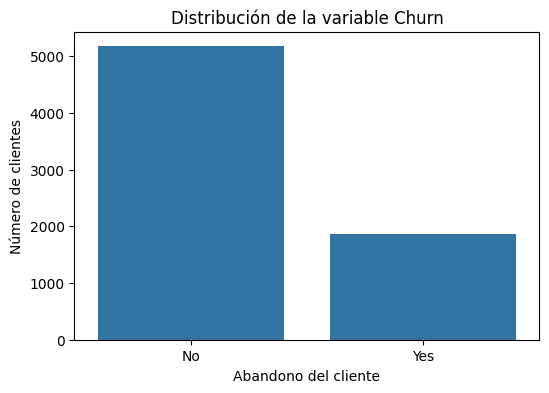

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribución de la variable Churn")
plt.xlabel("Abandono del cliente")
plt.ylabel("Número de clientes")

plt.show()

La gráfica confirma visualmente que existe una mayor cantidad de clientes que permanecieron en la compañía que de clientes que abandonaron el servicio.

La diferencia entre ambas categorías coincide con los porcentajes obtenidos anteriormente y permite observar claramente el desbalance moderado de la variable objetivo.

## 2.16 Visualización 2: abandono según tipo de contrato

A continuación se analizará la proporción de clientes que abandonaron o permanecieron en la empresa según el tipo de contrato contratado.

Para facilitar la comparación se calculará el porcentaje correspondiente a cada categoría de `Churn` dentro de cada tipo de contrato.

In [16]:
tabla_contrato = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

tabla_contrato.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


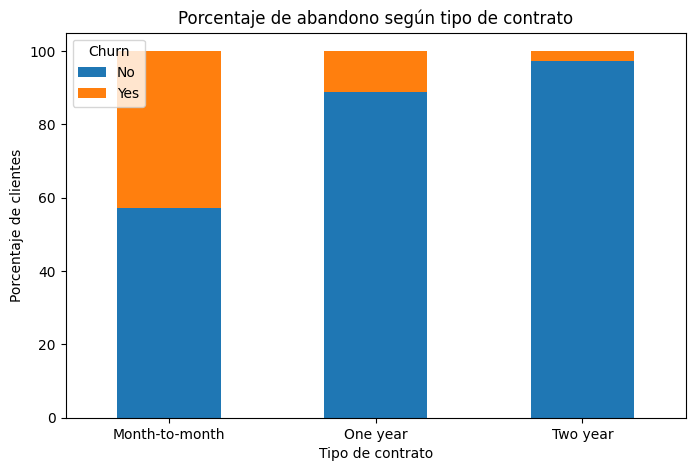

In [17]:
tabla_contrato.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Porcentaje de abandono según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Porcentaje de clientes")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

Se observa una diferencia importante en el comportamiento de abandono según el tipo de contrato.

Los clientes con contratos **Month-to-month** presentan aproximadamente un **42.71 % de abandono**.

En cambio, entre quienes tienen contratos de **un año**, el porcentaje de abandono es aproximadamente **11.27 %**, mientras que en los contratos de **dos años** disminuye aproximadamente a **2.83 %**.

Por lo tanto, dentro de este conjunto de datos existe una asociación entre el tipo de contrato y el comportamiento de abandono.

Sin embargo, este análisis exploratorio no permite afirmar que el tipo de contrato sea la causa directa del abandono, debido a que pueden existir otras características relacionadas con ambos factores.

## 2.17 Visualización 3: antigüedad de los clientes según `Churn`

Se utilizará un diagrama de caja (*boxplot*) para comparar la distribución de la antigüedad (`tenure`) entre los clientes que permanecieron y aquellos que abandonaron la compañía.

Este tipo de gráfica permite observar la posición de la mediana, la dispersión de los valores y las diferencias existentes entre ambos grupos.

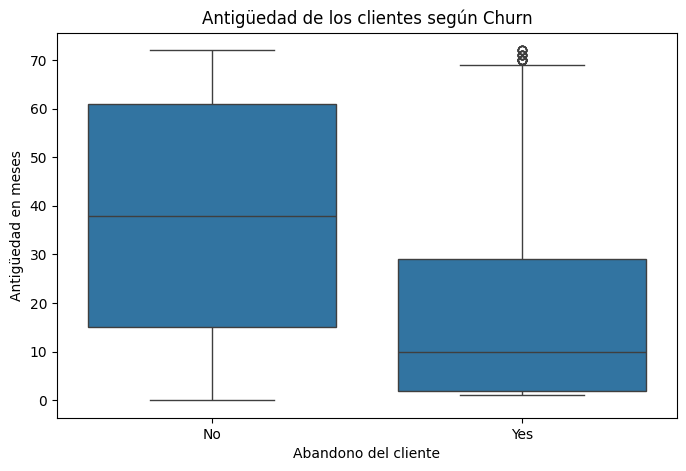

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Antigüedad de los clientes según Churn")
plt.xlabel("Abandono del cliente")
plt.ylabel("Antigüedad en meses")

plt.show()

La distribución muestra que los clientes que abandonaron la compañía tienden a concentrarse en valores menores de antigüedad.

Por otra parte, los clientes que permanecieron presentan, en general, una mayor cantidad de meses como usuarios del servicio.

Esto indica que dentro del conjunto de datos existe un patrón entre la antigüedad del cliente y el comportamiento de abandono.

Al igual que en los análisis anteriores, esta relación representa una asociación encontrada en los datos y no demuestra por sí misma una relación de causa y efecto.

## 2.18 Matriz de correlación entre variables numéricas

Como parte del análisis exploratorio se estudiará la correlación existente entre las principales variables numéricas.

La correlación de Pearson permite medir el grado de relación lineal entre dos variables mediante valores comprendidos entre -1 y 1.

- Valores cercanos a **1** representan una relación lineal positiva.
- Valores cercanos a **-1** representan una relación lineal negativa.
- Valores cercanos a **0** indican que existe poca relación lineal.

Para incluir la variable objetivo dentro de este análisis se creará únicamente una representación numérica auxiliar de `Churn`:

- `No` = 0
- `Yes` = 1

Esta transformación se realizará exclusivamente para el análisis exploratorio y no modificará el conjunto de datos original.

In [19]:
# Copia auxiliar únicamente para el análisis de correlación
df_corr = df.copy()

# Conversión temporal de TotalCharges
df_corr["TotalCharges"] = pd.to_numeric(
    df_corr["TotalCharges"],
    errors="coerce"
)

# Representación numérica temporal de la variable objetivo
df_corr["Churn_num"] = df_corr["Churn"].map({
    "No": 0,
    "Yes": 1
})

variables_correlacion = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn_num"
]

correlaciones = df_corr[
    variables_correlacion
].corr()

correlaciones

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_num
SeniorCitizen,1.000000,0.016567,0.220173,0.102411,0.150889
tenure,0.016567,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn_num,0.150889,-0.352229,0.193356,-0.199484,1.000000


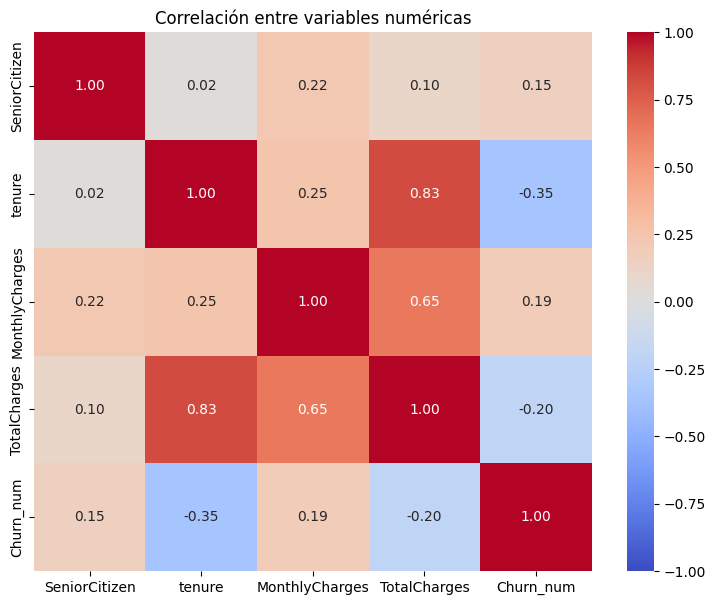

In [20]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlación entre variables numéricas"
)

plt.show()

### Correlación de las variables con `Churn`

Además del mapa de calor, se mostrarán de manera ordenada los coeficientes de correlación de las variables numéricas con la variable objetivo.

Esto permitirá identificar con mayor facilidad cuáles presentan una relación lineal positiva o negativa con el abandono de clientes.

In [21]:
correlacion_churn = (
    correlaciones["Churn_num"]
    .sort_values(ascending=False)
    .to_frame("Correlación con Churn")
)

correlacion_churn

,Correlación con Churn
Churn_num,1.000000
MonthlyCharges,0.193356
SeniorCitizen,0.150889
TotalCharges,-0.199484
tenure,-0.352229


### Interpretación de la matriz de correlación

La matriz de correlación permite complementar los análisis gráficos realizados anteriormente.

Los valores positivos indican que, conforme aumenta una variable, también tiende a aumentar la presencia de la categoría `Churn = Yes`, mientras que los valores negativos indican una relación en sentido contrario.

Entre las variables analizadas se observan diferencias en su relación con `Churn`. La antigüedad (`tenure`) presenta una relación negativa con el abandono, lo cual coincide con el análisis realizado mediante el boxplot: los clientes con mayor antigüedad tienden a permanecer con mayor frecuencia en la compañía.

Por otra parte, algunas variables presentan relaciones positivas con `Churn`, aunque con diferente intensidad.

También pueden observarse relaciones entre las propias variables predictoras. Por ejemplo, `TotalCharges` se encuentra relacionado con otras características como la antigüedad y los cargos mensuales, lo cual es razonable debido a que representa el gasto acumulado de cada cliente.

Es importante señalar que una correlación, incluso cuando presenta un valor relativamente alto, **no demuestra una relación de causa y efecto**. Este análisis únicamente permite identificar asociaciones lineales presentes dentro del conjunto de datos.

## 2.19 Principales hallazgos de la comprensión de los datos

La exploración del conjunto de datos permitió identificar diferentes características importantes relacionadas con su estructura, calidad y comportamiento.

1. El conjunto de datos contiene **7,043 registros y 21 variables**.

2. Cada registro corresponde a un cliente diferente, ya que existen 7,043 valores únicos en `customerID`.

3. No se identificaron registros completamente duplicados.

4. La variable `TotalCharges` presenta una inconsistencia en su tipo de dato. Aunque representa una cantidad monetaria, Pandas la interpreta como texto debido a que existen **11 registros con espacios en blanco**.

5. Los 11 registros con espacios en `TotalCharges` corresponden a clientes cuya antigüedad (`tenure`) es igual a 0 meses.

6. La variable objetivo `Churn` presenta un desbalance moderado: aproximadamente **73.46 %** de los clientes permanecieron en la compañía y **26.54 %** abandonaron el servicio.

7. Los clientes con contratos mensuales presentan una proporción de abandono considerablemente mayor que aquellos que cuentan con contratos de uno o dos años.

8. Los clientes que abandonaron la compañía tienden a presentar una menor antigüedad que quienes permanecieron.

9. Los histogramas mostraron que las variables numéricas presentan diferentes distribuciones y escalas. `tenure` refleja distintos niveles de antigüedad, `MonthlyCharges` presenta una amplia variedad de cargos mensuales y `TotalCharges` muestra una distribución más dispersa debido a que representa valores acumulados.

10. La matriz de correlación permitió complementar los análisis individuales e identificar relaciones entre las variables numéricas y `Churn`. Particularmente, la relación negativa entre `tenure` y el abandono coincide con lo observado anteriormente en el análisis gráfico de la antigüedad de los clientes.

11. `MonthlyCharges` presenta una relación positiva con `Churn`, mientras que `tenure` presenta una relación negativa. Estas asociaciones indican que determinadas características numéricas pueden estar relacionadas con el comportamiento de abandono.

12. También se identificaron relaciones entre algunas variables predictoras, especialmente entre `TotalCharges`, `tenure` y `MonthlyCharges`, debido a que el gasto total de un cliente depende en parte de cuánto tiempo ha permanecido en la compañía y de los cargos que recibe mensualmente.

En conjunto, estos hallazgos permiten comprender mejor la estructura y calidad del conjunto de datos, así como identificar patrones relacionados con el abandono de clientes.

Las relaciones observadas representan asociaciones presentes en los datos y no deben interpretarse automáticamente como relaciones de causa y efecto. Si posteriormente se continuara con las siguientes etapas de CRISP-DM, estos resultados podrían utilizarse como punto de partida para la preparación de los datos y el desarrollo de modelos de clasificación.

# Conclusiones

El desarrollo de las dos primeras fases de la metodología CRISP-DM permitió comprender tanto el problema del abandono de clientes como las principales características del conjunto de datos **Telco Customer Churn**.

Durante la exploración se identificaron **7,043 registros y 21 variables**, correspondientes a información demográfica, servicios contratados, condiciones comerciales y datos de facturación de los clientes. También se comprobó que no existen registros completamente duplicados y que cada `customerID` corresponde a un cliente diferente.

La revisión de la calidad de los datos permitió detectar una inconsistencia importante en la variable `TotalCharges`. Aunque representa una cantidad monetaria, se encuentra almacenada como texto debido a la existencia de **11 registros con espacios en blanco**. Estos valores no fueron detectados inicialmente como nulos mediante `isnull()`, lo que demuestra la importancia de realizar una exploración detallada de las variables y no depender únicamente de una sola herramienta para evaluar la calidad de los datos.

Respecto a la variable objetivo, se encontró que aproximadamente el **73.46 %** de los clientes permanecieron en la compañía y el **26.54 %** abandonaron el servicio, por lo que existe un desbalance moderado entre ambas clases.

Las visualizaciones también permitieron identificar patrones relevantes. Los clientes con contratos mensuales presentan una proporción de abandono mayor que quienes cuentan con contratos de uno o dos años. Asimismo, los clientes que abandonaron la compañía tienden a presentar una menor antigüedad.

Estos resultados muestran asociaciones presentes dentro del conjunto de datos, pero no permiten establecer por sí mismos relaciones de causa y efecto. Para determinar la capacidad predictiva de estas y otras variables sería necesario continuar posteriormente con las fases de preparación, modelado y evaluación de CRISP-DM.

Este análisis permitió comprender la estructura y calidad del conjunto de datos, identificar posibles problemas que deberán ser considerados en etapas posteriores y reconocer algunas características asociadas con el abandono de clientes. Esto proporciona una base adecuada para continuar con el desarrollo de un modelo de clasificación.

# Referencias

- Kaggle. *Telco Customer Churn*. Conjunto de datos utilizado para el desarrollo del análisis.  
  https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- Pandas Development Team. *Pandas Documentation*.  
  https://pandas.pydata.org/docs/

- Matplotlib Development Team. *Matplotlib Documentation*.  
  https://matplotlib.org/stable/

- Seaborn Development Team. *Seaborn Documentation*.  
  https://seaborn.pydata.org/